In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from pygris import tracts 
from pygris.data import get_lodes
import matplotlib.pyplot as plt

Read Files

In [2]:
NY_2009_commute_df=pd.read_csv("D:/LMU_Life/Housing/project/LODES Data/ny_od_main_JT01_2009.csv")
NY_2010_commute_df=pd.read_csv("D:/LMU_Life/Housing/project/LODES Data/ny_od_main_JT01_2010.csv")
NY_2011_commute_df=pd.read_csv("D:/LMU_Life/Housing/project/LODES Data/ny_od_main_JT01_2011.csv")
NY_2012_commute_df=pd.read_csv("D:/LMU_Life/Housing/project/LODES Data/ny_od_main_JT01_2012.csv")
NY_2013_commute_df=pd.read_csv("D:/LMU_Life/Housing/project/LODES Data/ny_od_main_JT01_2013.csv")
NY_2014_commute_df=pd.read_csv("D:/LMU_Life/Housing/project/LODES Data/ny_od_main_JT01_2014.csv")
NY_2015_commute_df=pd.read_csv("D:/LMU_Life/Housing/project/LODES Data/ny_od_main_JT01_2015.csv")
NY_2016_commute_df=pd.read_csv("D:/LMU_Life/Housing/project/LODES Data/ny_od_main_JT01_2016.csv")
NY_2017_commute_df=pd.read_csv("D:/LMU_Life/Housing/project/LODES Data/ny_od_main_JT01_2017.csv")
NY_2018_commute_df=pd.read_csv("D:/LMU_Life/Housing/project/LODES Data/ny_od_main_JT01_2018.csv")
NY_2019_commute_df=pd.read_csv("D:/LMU_Life/Housing/project/LODES Data/ny_od_main_JT01_2019.csv")
NY_2020_commute_df=pd.read_csv("D:/LMU_Life/Housing/project/LODES Data/ny_od_main_JT01_2020.csv")

In [ ]:
def get_hudson_commuters(commute_df, tracts_hudson):
    """
    Filters data for workers commuting to Hudsdon Yards
    """
    df = commute_df.assign(
        w_trct=commute_df["w_geocode"].astype(str).str.slice(stop=11),
        h_trct=commute_df["h_geocode"].astype(str).str.slice(stop=11)
    )

    return (
        df.query('w_trct in @tracts_hudson')
        .groupby(["h_trct", "w_trct"], as_index=False)
        .agg({"S000": "sum"})
        .rename(columns={"S000": "hudson_workers"})
    )


In [ ]:
def get_total_workers(commute_df):
    """
    Aggregates total workers per home tract
    """
    return (
        commute_df
        .assign(h_trct=commute_df["h_geocode"].astype(str).str.slice(stop=11))
        .groupby("h_trct", as_index=False)
        .agg({"S000": "sum"})
        .rename(columns={"S000": "total_workers"})
    )


In [ ]:
def compute_hudson_share(hudson_df, total_df):
    """
    Compute commuters per 1000.
    """
    return (
        hudson_df
        .merge(total_df, on="h_trct", how="left")
        .assign(hudson_workers_per_1000=lambda df: 1000 * df["hudson_workers"] / df["total_workers"])
    )

In [ ]:
def attach_geometries_and_distance(commute_stats_df, NY_tracts, crs_epsg=2263):
    """
    Add geometry and find distance
    """
    # Merge home tract geometry
    home_geom = NY_tracts.merge(commute_stats_df, left_on="GEOID", right_on="h_trct", how="left")

    # Merge work tract geometry
    w_geom = NY_tracts[["GEOID", "geometry"]].rename(columns={"GEOID": "w_trct", "geometry": "w_geometry"})
    merged = home_geom.merge(w_geom, on="w_trct", how="left")

    # Reproject and compute distance
    merged = merged.to_crs(epsg=crs_epsg)
    merged["w_geometry"] = merged["w_geometry"].to_crs(epsg=crs_epsg)
    merged["tract_distance"] = merged.geometry.distance(merged["w_geometry"])
    merged["distance_km"] = (merged["tract_distance"] * 0.0003048).round(2)

    return merged


Get tract geometry for NYC

In [7]:
NY_tracts = tracts(state = "NY", cb = True, 
                   county=['Bronx County', 'Kings County', 'New York County', 'Queens County', 'Richmond County'
],
                    year = 2020, cache = True)

Using FIPS code '36' for input 'NY'
Using FIPS code '005' for input 'Bronx County'
Using FIPS code '047' for input 'Kings County'
Using FIPS code '061' for input 'New York County'
Using FIPS code '081' for input 'Queens County'
Using FIPS code '085' for input 'Richmond County'


Apply Functions

In [8]:
tracts_hudson = ['36061009903', '36061009902', '36061009901', '36061009900']

# 2009
hudson_2009 = get_hudson_commuters(NY_2009_commute_df, tracts_hudson)
total_2009 = get_total_workers(NY_2009_commute_df)
hudson_2009_stats = compute_hudson_share(hudson_2009, total_2009)
gdf_2009 = attach_geometries_and_distance(hudson_2009_stats, NY_tracts)

# 2010
hudson_2010 = get_hudson_commuters(NY_2010_commute_df, tracts_hudson)
total_2010 = get_total_workers(NY_2010_commute_df)
hudson_2010_stats = compute_hudson_share(hudson_2010, total_2010)
gdf_2010 = attach_geometries_and_distance(hudson_2010_stats, NY_tracts)

# 2011
hudson_2011 = get_hudson_commuters(NY_2011_commute_df, tracts_hudson)
total_2011 = get_total_workers(NY_2011_commute_df)
hudson_2011_stats = compute_hudson_share(hudson_2011, total_2011)
gdf_2011 = attach_geometries_and_distance(hudson_2011_stats, NY_tracts)

# 2012
hudson_2012 = get_hudson_commuters(NY_2012_commute_df, tracts_hudson)
total_2012 = get_total_workers(NY_2012_commute_df)
hudson_2012_stats = compute_hudson_share(hudson_2012, total_2012)
gdf_2012 = attach_geometries_and_distance(hudson_2012_stats, NY_tracts)

# 2013
hudson_2013 = get_hudson_commuters(NY_2013_commute_df, tracts_hudson)
total_2013 = get_total_workers(NY_2013_commute_df)
hudson_2013_stats = compute_hudson_share(hudson_2013, total_2013)
gdf_2013 = attach_geometries_and_distance(hudson_2013_stats, NY_tracts)

# 2014
hudson_2014 = get_hudson_commuters(NY_2014_commute_df, tracts_hudson)
total_2014 = get_total_workers(NY_2014_commute_df)
hudson_2014_stats = compute_hudson_share(hudson_2014, total_2014)
gdf_2014 = attach_geometries_and_distance(hudson_2014_stats, NY_tracts)

# 2015
hudson_2015 = get_hudson_commuters(NY_2015_commute_df, tracts_hudson)
total_2015 = get_total_workers(NY_2015_commute_df)
hudson_2015_stats = compute_hudson_share(hudson_2015, total_2015)
gdf_2015 = attach_geometries_and_distance(hudson_2015_stats, NY_tracts)

# 2016
hudson_2016 = get_hudson_commuters(NY_2016_commute_df, tracts_hudson)
total_2016 = get_total_workers(NY_2016_commute_df)
hudson_2016_stats = compute_hudson_share(hudson_2016, total_2016)
gdf_2016 = attach_geometries_and_distance(hudson_2016_stats, NY_tracts)

# 2017
hudson_2017 = get_hudson_commuters(NY_2017_commute_df, tracts_hudson)
total_2017 = get_total_workers(NY_2017_commute_df)
hudson_2017_stats = compute_hudson_share(hudson_2017, total_2017)
gdf_2017 = attach_geometries_and_distance(hudson_2017_stats, NY_tracts)

# 2018
hudson_2018 = get_hudson_commuters(NY_2018_commute_df, tracts_hudson)
total_2018 = get_total_workers(NY_2018_commute_df)
hudson_2018_stats = compute_hudson_share(hudson_2018, total_2018)
gdf_2018 = attach_geometries_and_distance(hudson_2018_stats, NY_tracts)

# 2019
hudson_2019 = get_hudson_commuters(NY_2019_commute_df, tracts_hudson)
total_2019 = get_total_workers(NY_2019_commute_df)
hudson_2019_stats = compute_hudson_share(hudson_2019, total_2019)
gdf_2019 = attach_geometries_and_distance(hudson_2019_stats, NY_tracts)

# 2020
hudson_2020 = get_hudson_commuters(NY_2020_commute_df, tracts_hudson)
total_2020 = get_total_workers(NY_2020_commute_df)
hudson_2020_stats = compute_hudson_share(hudson_2020, total_2020)
gdf_2020 = attach_geometries_and_distance(hudson_2020_stats, NY_tracts)


Concat and create bins

In [ ]:

gdf_all_years = pd.concat(
    [gdf_2009.assign(year=2009),
     gdf_2010.assign(year=2010),
     gdf_2011.assign(year=2011),
     gdf_2012.assign(year=2012),
     gdf_2013.assign(year=2013),
     gdf_2014.assign(year=2014),
     gdf_2015.assign(year=2015),
     gdf_2016.assign(year=2016),
     gdf_2017.assign(year=2017),
     gdf_2018.assign(year=2018),
     gdf_2019.assign(year=2019),
     gdf_2020.assign(year=2020)],
    ignore_index=True
)


gdf_all_years["period"] = gdf_all_years["year"].apply(lambda y: "Before 2015" if y < 2015 else "After 2015 (inclusive)")


bin_edges = range(0, int(gdf_all_years["distance_km"].max()) + 10, 5)
bin_labels = [f"{i}-{i+5} km" for i in bin_edges[:-1]]
gdf_all_years["distance_bin_5km"] = pd.cut(gdf_all_years["distance_km"], bins=bin_edges, labels=bin_labels)
custom_edges = [0, 1, 3, 5, 7, 10, float("inf")]
custom_labels = ["<1 km", "1–3 km", "3–5 km", "5–7 km", "7–10 km", ">10 km"]


gdf_all_years["distance_bin_custom"] = pd.cut(
    gdf_all_years["distance_km"],
    bins=custom_edges,
    labels=custom_labels,
    right=False  
)

C:\Users\fiodo\AppData\Local\Temp\ipykernel_19140\3627188717.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby(["period", "distance_bin_custom"])["hudson_workers_per_1000"]


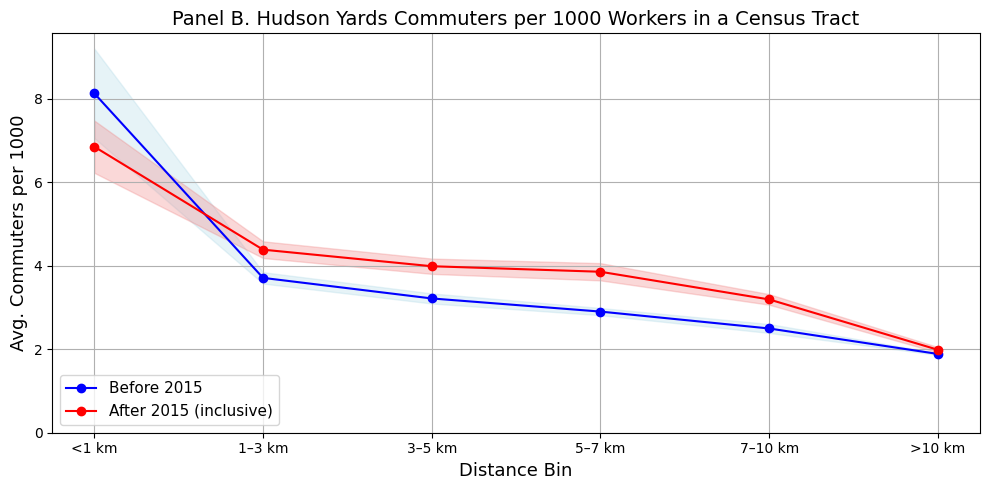

In [32]:
grouped = (
    gdf_all_years
    .groupby(["period", "distance_bin_custom"])["hudson_workers_per_1000"]
    .agg(['mean', 'std', 'count'])
    .reset_index()
    .rename(columns={'mean': 'avg', 'std': 'stddev', 'count': 'n'})
)

grouped['ci95'] = 1.96 * grouped['stddev'] / np.sqrt(grouped['n'])


all_bins = ["<1 km", "1–3 km", "3–5 km", "5–7 km", "7–10 km", ">10 km"]


plt.figure(figsize=(10, 5))


for period, color, ci_color in [("Before 2015", "blue", "lightblue"), ("After 2015 (inclusive)", "red", "lightcoral")]:
    df = (
        grouped[grouped["period"] == period]
        .set_index("distance_bin_custom")
        .reindex(all_bins)
    )

    plt.plot(all_bins, df["avg"], label=period, color=color, marker='o')
    plt.fill_between(all_bins,
                     df["avg"] - df["ci95"],
                     df["avg"] + df["ci95"],
                     color=ci_color, alpha=0.3,
                     label='_nolegend_')


plt.title("Panel B. Hudson Yards Commuters per 1000 Workers in a Census Tract", fontsize=14)
plt.xlabel("Distance Bin", fontsize=13)
plt.ylabel("Avg. Commuters per 1000", fontsize=13)    
plt.legend(fontsize=11,loc='lower left')
plt.ylim(bottom=0)
plt.tight_layout()
plt.grid(True)
plt.show()